In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
import tensorflow as tf
from fast_plate_ocr.train.model.layers import MaxBlurPooling2D

plate_model = YOLO(r"F:\models\plate_detector_best.pt")

ocr_model = tf.keras.models.load_model(
    r"F:\models\ocr_best.keras",
    compile=False,
    safe_mode=False
)

print("Both trained models loaded successfully!")


Both trained models loaded successfully!


Total images: 12

Image: 003a5aaf6d17c917.jpg
Detected Number Plate: C63AMGG


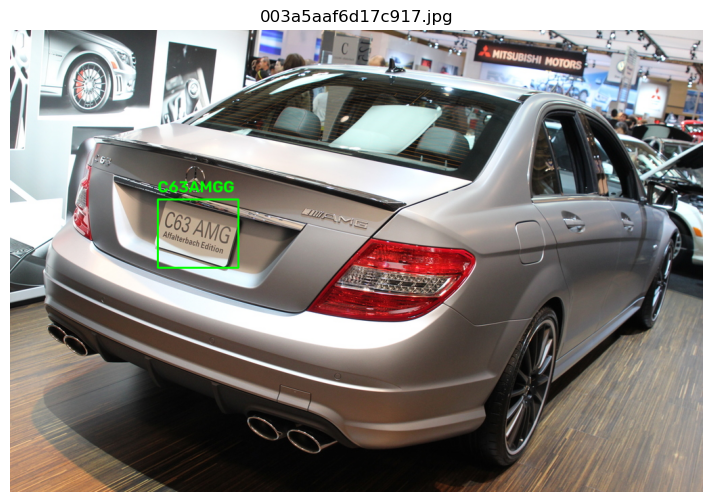


Image: 064a8def3049d040.jpg
Detected Number Plate: 5752FXX


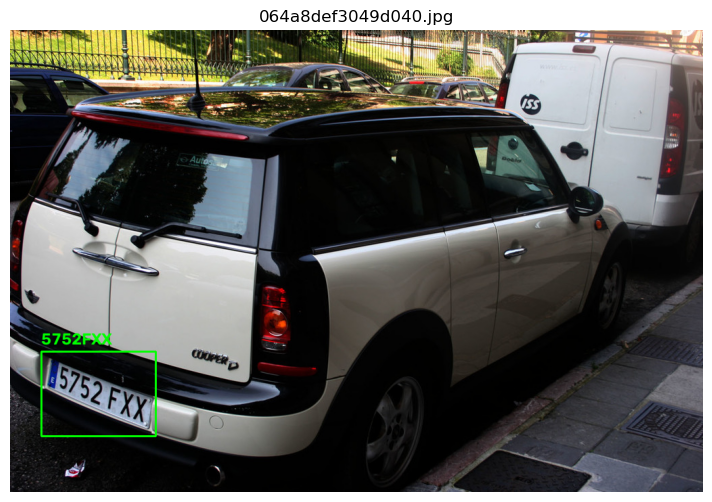


Image: 0673b967f8c68eec.jpg
Detected Number Plate: T15OAP


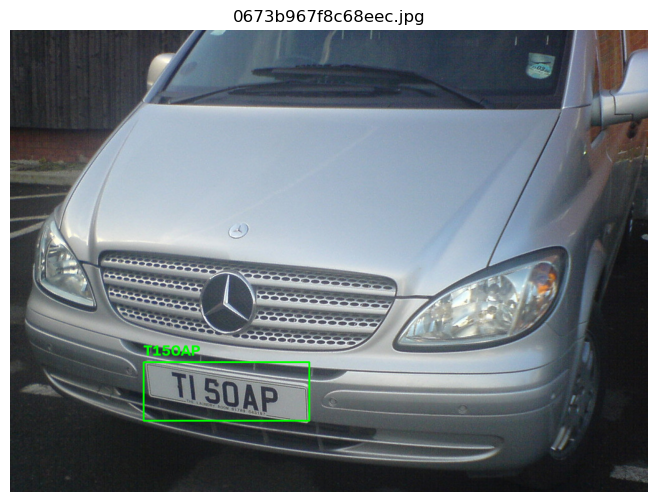


Image: 06b024413ad385a7.jpg
Detected Number Plate: RC2808


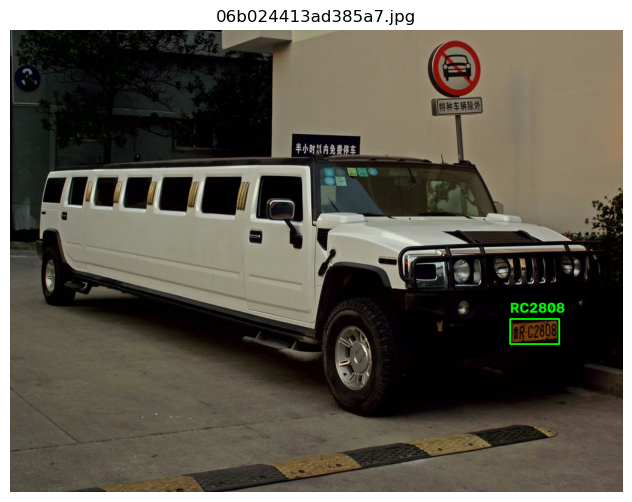


Image: 0787b0fa95f545a5.jpg
Detected Number Plate: BJ03LB


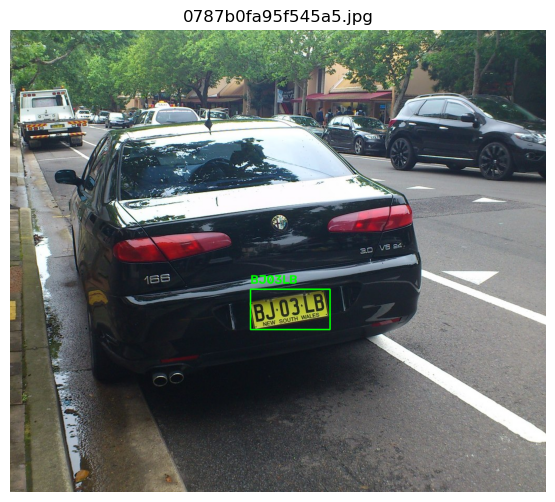


Image: 0cacb08195a3e2d7.jpg
Detected Number Plate: AVF198


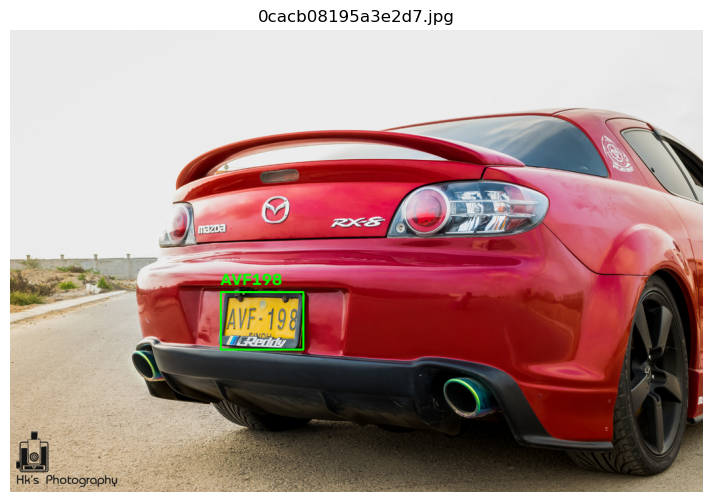


Image: 9k_ (7).jpg
Detected Number Plate: 01AS4444
Detected Number Plate: D1AG4444
Detected Number Plate: 01AS444_44


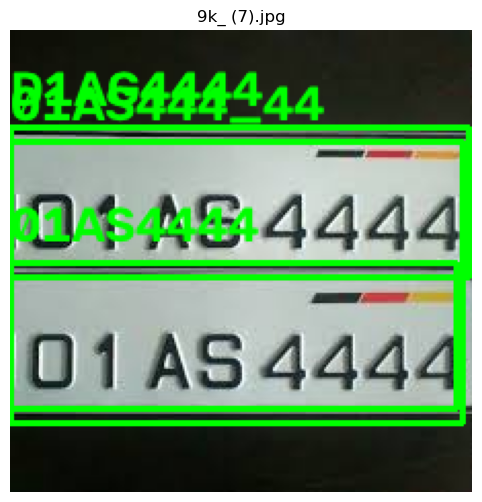


Image: images (11).jpg
Detected Number Plate: DL6CAB123X


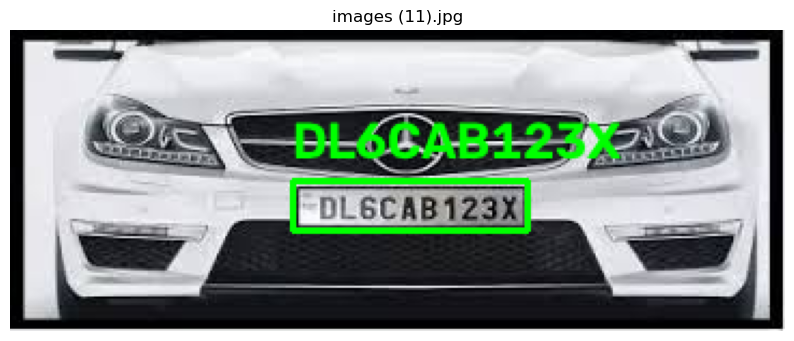


Image: images (13).jpg
Detected Number Plate: MH12DE1433


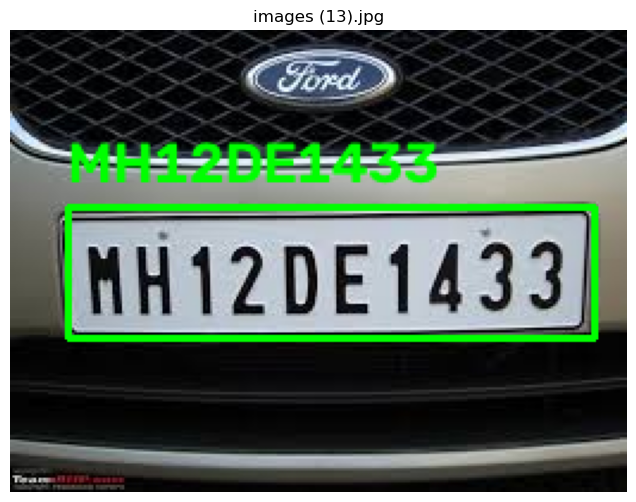


Image: images (14).jpg
Detected Number Plate: G526JHD


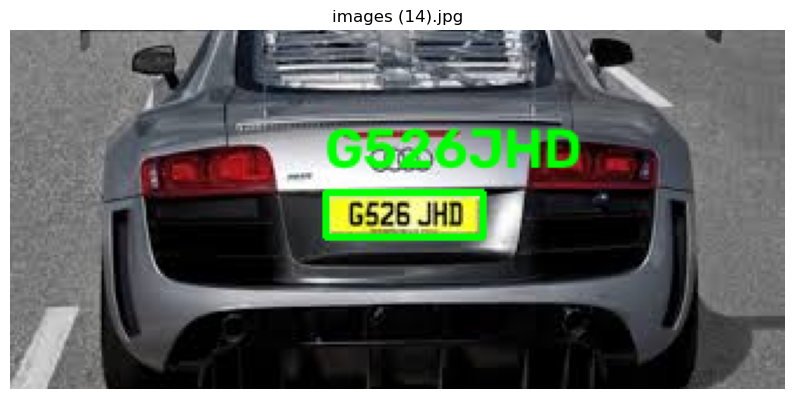


Image: images (18).jpg
Detected Number Plate: M003B_5


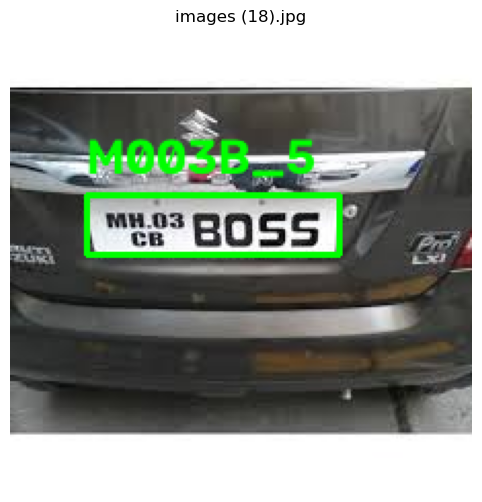


Image: images (2).jpg
Detected Number Plate: DL2CP5428


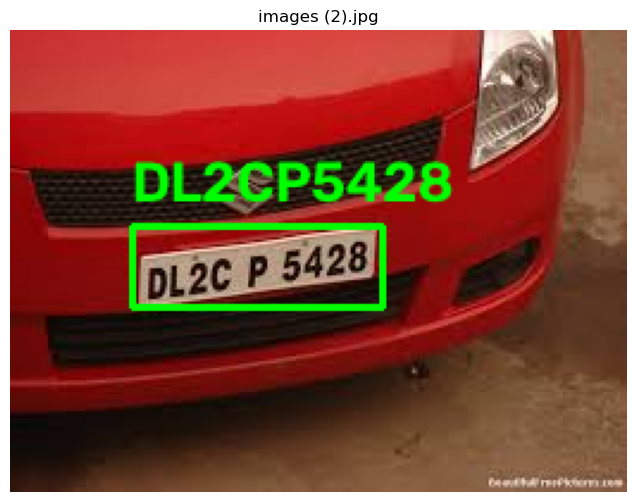


Implementation completed for all 12 images.


In [2]:

import os

image_folder = r"F:\models\test_images"

image_files = [
    os.path.join(image_folder, f)
    for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
][:12]

alphabet = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ_"

print("Total images:", len(image_files))

for image_path in image_files:
    image = cv2.imread(image_path)

    if image is None:
        continue

    results = plate_model.predict(image, conf=0.25, verbose=False)
    print("\nImage:", os.path.basename(image_path))

    if len(results[0].boxes) == 0:
        print("Number plate not detected")

    for box in results[0].boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        crop = cv2.resize(crop, (128, 64)).astype(np.float32)
        crop = np.expand_dims(crop, axis=0)

        prediction = ocr_model.predict(crop, verbose=0)["plate"][0]

        plate_text = "".join(
            alphabet[i] for i in np.argmax(prediction, axis=-1)
        ).rstrip("_")

        print("Detected Number Plate:", plate_text)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            image, plate_text, (x1, max(y1 - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2
        )

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(os.path.basename(image_path))
    plt.axis("off")
    plt.show()

print("\nImplementation completed for all 12 images.")

